# ViT-Tiny_16 from scratch trên Imagenette

Tự xây dựng một Vision Transformer nhỏ (patch 16×16, embed 64, 4 head, 4 layer, MLP 128) và huấn luyện **từ tham số khởi tạo ngẫu nhiên** để phân loại 10 lớp Imagenette; sau đó cải tiến bằng **Convolutional Stem** và trực quan hoá attention của token [CLS].

**Luồng dữ liệu:** Dataset → Tiền xử lý → DataLoader → Model (Patch → Attention → Classifier) → Loss → Optimizer

| Mục | Nội dung |
|---|---|
| 1 | Cấu hình (một file YAML duy nhất) |
| 2 | Dataset → Tiền xử lý → DataLoader |
| 3 | Tokenization: ảnh thành 196 "từ" 16×16 |
| 4 | Model: hợp đồng shape & số tham số |
| 5 | Huấn luyện bản gốc (patch + `nn.Linear`) |
| 6 | Huấn luyện bản cải tiến (Convolutional Stem) |
| 7 | Đường cong huấn luyện & so sánh |
| 8 | Đánh giá trên tập test |
| 9 | Position embedding đã học |
| 10 | Attention map của [CLS] |
| 11 | Cải tiến 2: Locality trong Transformer block (LeFF) |
| 12 | Huấn luyện ViT-Tiny_16 + LeFF |
| 13 | Huấn luyện ViT-Tiny_16 + ConvStem + LeFF |
| 14 | So sánh hai kiến trúc: bản gốc vs ConvStem + LeFF |
| 15 | Kết quả 4 cấu hình (ablation 2×2) |
| 16 | Đánh giá trên tập test |
| 17 | Attention map của [CLS]: 4 cấu hình |
| 18 | Thảo luận |

Code nằm trong các module (`configs/`, `datasets/`, `models/`, `utils/`, `train.py`, `eval.py`); notebook chỉ gọi chúng. Kiến trúc được giải thích chi tiết trong [ARCHITECTURE.md](ARCHITECTURE.md).

> **Ghi chú thực thi.** Notebook được chạy trong hai phiên kernel. **Phiên 1** chạy mục 1–10, trong đó có huấn luyện hai run đầu (mục 5, 6). Phiên này bị lỗi backend matplotlib: `eval.py` gọi `matplotlib.use("Agg")` lúc import nên các hình không hiển thị (đã sửa). **Phiên 2** chạy lại **mọi ô trừ hai ô huấn luyện ở mục 5 và 6**, rồi chạy tiếp mục 11–18, gồm huấn luyện hai run LeFF. Output của hai ô huấn luyện được giữ nguyên từ phiên 1 (cũng nằm trong `outputs/<run>/train_log.txt`), nên số thứ tự thực thi `[6]`, `[7]` xuất hiện hai lần. Các mục sau đọc kết quả hai run đó từ `outputs/` (`history.json`, `best.pt`), không huấn luyện lại.

> **Liêm chính học thuật.** Không dùng bất kỳ code, checkpoint hay trọng số pretrained nào (không `timm`, không HuggingFace, không `torchvision.models`). Mọi tham số được khởi tạo ngẫu nhiên trong `ViT._init_weights`. Mỗi run đánh giá model **trước khi train** (epoch 0) và in loss từ iteration đầu tiên, để thấy quá trình học bắt đầu từ mức ngẫu nhiên.

In [1]:
%matplotlib inline
import platform, time
import torch, torchvision, yaml
import matplotlib.pyplot as plt
from IPython.display import Image, display

from configs import load_config
from datasets import build_dataloaders, class_names
from models import build_model
from utils import count_parameters, format_shape_table, load_history, trace_shapes
from utils.visualize import (denormalize, plot_history, plot_position_similarity)
from train import run_training
from eval import run_eval
from visualize_attention import run_visualize

print(f"Python {platform.python_version()} | torch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"CUDA: {torch.cuda.is_available()} | CPU threads: {torch.get_num_threads()}")

Python 3.12.10 | torch 2.13.0+cpu | torchvision 0.28.0+cpu
CUDA: False | CPU threads: 12


## 1. Cấu hình

Mọi hyperparameter nằm trong `configs/config.yaml`; `load_config` đọc file đó thành dataclass có kiểu, báo lỗi nếu thiếu hoặc gõ sai khoá. Hai run bên dưới dùng **cùng một file**, chỉ ghi đè `model.stem` và `experiment.name`.

In [2]:
CONFIG = "configs/config.yaml"
cfg = load_config(CONFIG)
print(yaml.safe_dump(cfg.to_dict(), sort_keys=False, allow_unicode=True))

experiment:
  name: vit_tiny_16
  seed: 42
  output_dir: outputs
  device: auto
  num_threads: 0
data:
  root: data
  size: 320px
  download: true
  image_size: 224
  resize_size: 256
  rrc_scale:
  - 0.35
  - 1.0
  hflip_prob: 0.5
  mean:
  - 0.485
  - 0.456
  - 0.406
  std:
  - 0.229
  - 0.224
  - 0.225
  num_classes: 10
  batch_size: 32
  num_workers: 8
  pin_memory: false
model:
  arch: ViT-Tiny_16
  stem: linear
  in_channels: 3
  patch_size: 16
  embed_dim: 64
  num_heads: 4
  depth: 4
  mlp_hidden: 128
  mlp_type: standard
  leff_kernel_size: 3
  qkv_bias: true
  attn_dropout: 0.0
  dropout: 0.1
  head_hidden: 0
  conv_stem_channels:
  - 24
  - 48
  - 64
  - 64
  init_std: 0.02
loss:
  name: cross_entropy
  label_smoothing: 0.1
optimizer:
  name: adamw
  lr: 0.0003
  weight_decay: 0.05
  betas:
  - 0.9
  - 0.999
scheduler:
  name: cosine
  warmup_epochs: 2
  min_lr: 1.0e-06
train:
  epochs: 20
  grad_clip: 1.0
  log_every: 50
  eval_before_training: true
visualize:
  num_images:

## 2. Dataset → Tiền xử lý → DataLoader

- **Dataset:** `torchvision.datasets.Imagenette(size="320px")`, 10 lớp, ảnh có cạnh ngắn 320px.
- **Tiền xử lý train:** `RandomResizedCrop(224)` + lật ngang → `ToTensor` → `Normalize`.
- **Tiền xử lý val:** `Resize(256)` + `CenterCrop(224)` → `ToTensor` → `Normalize`.
- **DataLoader:** mỗi batch có ảnh `(B, 3, 224, 224)` và nhãn `(B,)`.

train: 9469 ảnh | val: 3925 ảnh | 295 iter/epoch
Các lớp: ['tench', 'English springer', 'cassette player', 'chain saw', 'church', 'French horn', 'garbage truck', 'gas pump', 'golf ball', 'parachute']


images: (32, 3, 224, 224) torch.float32 | labels: (32,) torch.int64
giá trị sau Normalize: mean=-0.105, std=1.198


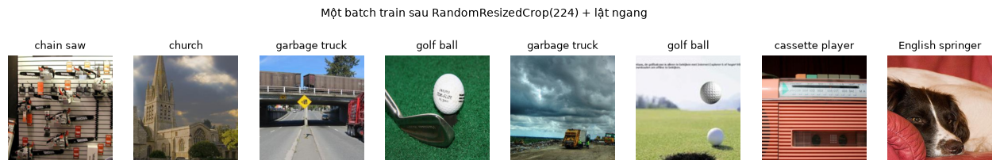

In [3]:
train_loader, val_loader = build_dataloaders(cfg.data)
names = class_names(train_loader.dataset)
print(f"train: {len(train_loader.dataset)} ảnh | val: {len(val_loader.dataset)} ảnh | {len(train_loader)} iter/epoch")
print("Các lớp:", names)

images, labels = next(iter(train_loader))
print("images:", tuple(images.shape), images.dtype, "| labels:", tuple(labels.shape), labels.dtype)
print(f"giá trị sau Normalize: mean={images.mean():.3f}, std={images.std():.3f}")

shown = denormalize(images[:8], cfg.data.mean, cfg.data.std)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, img, y in zip(axes, shown, labels[:8]):
    ax.imshow(img.permute(1, 2, 0)); ax.set_title(names[y], fontsize=9); ax.axis("off")
fig.suptitle("Một batch train sau RandomResizedCrop(224) + lật ngang", fontsize=10)
plt.show()

## 3. Tokenization: ảnh thành 196 "từ" 16×16

`PatchEmbedding` cắt ảnh 224×224 thành lưới 14×14 = **196 patch**, mỗi patch 16×16×3 = 768 số, chỉ bằng `reshape` + `permute`. Ô dưới đây làm **đúng phép biến đổi đó** rồi vẽ lại từng patch để kiểm tra bằng mắt. Patch được đánh số theo hàng: patch `k` nằm ở hàng `k // 14`, cột `k % 14`.

Sau đó mỗi patch đi qua `nn.Linear(768, 64)`, được nối thêm [CLS] và cộng position embedding `nn.Embedding(197, 64)`.

ảnh (1, 3, 224, 224) -> lưới patch (1, 14, 14, 3, 16, 16) -> chuỗi (1, 196, 768)
sau nn.Linear: (1, 196, 64) | sau [CLS] + position: (1, 197, 64)


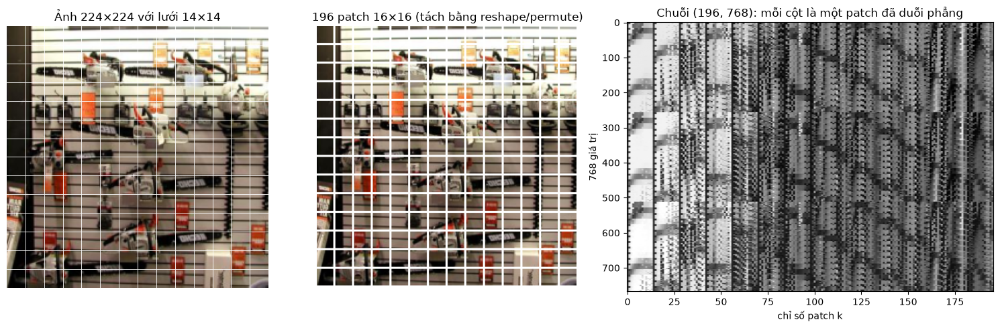

In [4]:
P, G = cfg.model.patch_size, cfg.data.image_size // cfg.model.patch_size
x = images[:1]                                                    # (1, 3, 224, 224)
patches = x.reshape(1, 3, G, P, G, P).permute(0, 2, 4, 1, 3, 5)   # (1, 14, 14, 3, 16, 16)
flat = patches.reshape(1, G * G, 3 * P * P)                       # (1, 196, 768)
print("ảnh", tuple(x.shape), "-> lưới patch", tuple(patches.shape), "-> chuỗi", tuple(flat.shape))

model_demo = build_model(cfg.model, cfg.data.image_size, cfg.data.num_classes).eval()
with torch.no_grad():
    tok = model_demo.stem(x)                                      # (1, 196, 64)
    seq = model_demo.tokens(tok)                                  # (1, 197, 64)
print("sau nn.Linear:", tuple(tok.shape), "| sau [CLS] + position:", tuple(seq.shape))

img = denormalize(x, cfg.data.mean, cfg.data.std)[0]
pv = denormalize(patches.reshape(G * G, 3, P, P), cfg.data.mean, cfg.data.std).reshape(G, G, 3, P, P)
gap = 2
canvas = torch.ones(3, G * (P + gap), G * (P + gap))
for r in range(G):
    for c in range(G):
        canvas[:, r * (P + gap): r * (P + gap) + P, c * (P + gap): c * (P + gap) + P] = pv[r, c]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1, 1.4]})
axes[0].imshow(img.permute(1, 2, 0))
for k in range(1, G):
    axes[0].axhline(k * P - 0.5, color="w", lw=0.6); axes[0].axvline(k * P - 0.5, color="w", lw=0.6)
axes[0].set_title("Ảnh 224×224 với lưới 14×14")
axes[1].imshow(canvas.permute(1, 2, 0)); axes[1].set_title("196 patch 16×16 (tách bằng reshape/permute)")
axes[2].imshow(flat[0, :, :].T, aspect="auto", cmap="gray")
axes[2].set(title="Chuỗi (196, 768): mỗi cột là một patch đã duỗi phẳng", xlabel="chỉ số patch k", ylabel="768 giá trị")
for ax in axes[:2]: ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Model: hợp đồng shape & số tham số

Bảng dưới được sinh tự động bằng forward hook (`utils/shapes.py`) cho cả hai loại stem. Chỉ **stem** khác nhau; từ `tokens` trở đi, hai model giống hệt nhau vì Conv Stem cũng tạo đúng lưới 14×14 = 196 token.

In [5]:
x2 = images[:2]
for stem in ["linear", "conv"]:
    c = load_config(CONFIG, [f"model.stem={stem}"])
    m = build_model(c.model, c.data.image_size, c.data.num_classes)
    print(f"\n=== {c.model.arch} | stem = {stem} ===")
    print(", ".join(f"{k}={v:,}" for k, v in count_parameters(m).items()))
    print(format_shape_table(trace_shapes(m, x2)))


=== ViT-Tiny_16 | stem = linear ===
stem=49,216, tokens=12,672, blocks=133,888, norm=128, head=650, total=196,554
module            loại                       shape vào         shape ra    
----------------  -------------------------  ----------------  ------------
stem.proj         Linear                     (2, 196, 768)     (2, 196, 64)
stem              PatchEmbedding             (2, 3, 224, 224)  (2, 196, 64)
tokens.pos_embed  Embedding                  (197,)            (197, 64)   
tokens.dropout    Dropout                    (2, 197, 64)      (2, 197, 64)
tokens            ClsTokenPositionEmbedding  (2, 196, 64)      (2, 197, 64)
blocks.0          TransformerBlock           (2, 197, 64)      (2, 197, 64)
blocks.1          TransformerBlock           (2, 197, 64)      (2, 197, 64)
blocks.2          TransformerBlock           (2, 197, 64)      (2, 197, 64)
blocks.3          TransformerBlock           (2, 197, 64)      (2, 197, 64)
norm              LayerNorm                  (2, 

## 5. Huấn luyện bản gốc: patch 16×16 + `nn.Linear`

Hyperparameter: batch 32, AdamW lr 3e-4, 20 epoch, CrossEntropyLoss. Phần bổ sung (weight decay 0.05, warmup + cosine, label smoothing 0.1, grad clip, flip) được giải thích trong ARCHITECTURE.md §6.

Log bên dưới cho thấy **epoch 0** (model vừa khởi tạo, chưa học: loss ≈ ln 10 ≈ 2.30, accuracy ≈ 10%) và loss của **iteration 1**, sau đó loss giảm dần qua từng epoch. Log cũng được lưu ở `outputs/vit_tiny_16/train_log.txt`.

_Output của ô dưới đây được giữ nguyên từ phiên 1 (xem ghi chú ở đầu notebook)._

In [6]:
t0 = time.time()
cfg_base = load_config(CONFIG, ["model.stem=linear", "experiment.name=vit_tiny_16"])
run_base = run_training(cfg_base)
print(f"Tổng thời gian: {(time.time() - t0) / 60:.1f} phút")

21:24:54 | Run 'vit_tiny_16' | ViT-Tiny_16 | stem=linear | device=cpu


21:24:54 | Dữ liệu: 9469 ảnh train, 3925 ảnh val, 295 iter/epoch, batch_size=32


21:24:54 | Số tham số: stem=49,216, tokens=12,672, blocks=133,888, norm=128, head=650, total=196,554


21:25:19 | Luồng shape qua model:
module            loại                       shape vào         shape ra    
----------------  -------------------------  ----------------  ------------
stem.proj         Linear                     (2, 196, 768)     (2, 196, 64)
stem              PatchEmbedding             (2, 3, 224, 224)  (2, 196, 64)
tokens.pos_embed  Embedding                  (197,)            (197, 64)   
tokens.dropout    Dropout                    (2, 197, 64)      (2, 197, 64)
tokens            ClsTokenPositionEmbedding  (2, 196, 64)      (2, 197, 64)
blocks.0          TransformerBlock           (2, 197, 64)      (2, 197, 64)
blocks.1          TransformerBlock           (2, 197, 64)      (2, 197, 64)
blocks.2          TransformerBlock           (2, 197, 64)      (2, 197, 64)
blocks.3          TransformerBlock           (2, 197, 64)      (2, 197, 64)
norm              LayerNorm                  (2, 197, 64)      (2, 197, 64)
head.net          Linear                     (2, 64)  

21:25:27 | epoch  0 (khởi tạo ngẫu nhiên, chưa train) | val loss 2.3450 | val acc 5.02% | val acc5 48.33%


...

21:47:42 | epoch 20/20 | iter  250/295 | loss 1.3124 (avg 1.3874) | acc avg 61.54% | lr 1.05e-06 | 0.20s/iter


21:47:51 | epoch 20/20 | iter  295/295 | loss 1.3717 (avg 1.3886) | acc avg 61.56% | lr 1.00e-06 | 0.20s/iter


21:47:56 | ==> epoch 20/20 | train loss 1.3886 acc 61.56% | val loss 1.3615 acc 63.77% acc5 94.09% | best 63.77% | 59s  *best*


21:47:56 | Xong 20 epoch trong 22.5 phút | best val acc 63.77% | kết quả ở outputs\vit_tiny_16


Tổng thời gian: 23.1 phút


## 6. Huấn luyện bản cải tiến: Convolutional Stem

Thay `PatchEmbedding` bằng `ConvStem`: 4 lớp conv 3×3 stride 2 (+BN+ReLU) rồi conv 1×1, ra đúng lưới 14×14 × 64 (xem ARCHITECTURE.md §5). **Mọi thứ khác giữ nguyên**: cùng config, cùng seed, cùng số epoch.

_Output của ô dưới đây được giữ nguyên từ phiên 1 (xem ghi chú ở đầu notebook)._

In [7]:
t0 = time.time()
cfg_conv = load_config(CONFIG, ["model.stem=conv", "experiment.name=vit_tiny_16_convstem"])
run_conv = run_training(cfg_conv)
print(f"Tổng thời gian: {(time.time() - t0) / 60:.1f} phút")

21:47:59 | Run 'vit_tiny_16_convstem' | ViT-Tiny_16 | stem=conv | device=cpu


21:47:59 | Dữ liệu: 9469 ảnh train, 3925 ảnh val, 295 iter/epoch, batch_size=32


21:47:59 | Số tham số: stem=80,088, tokens=12,672, blocks=133,888, norm=128, head=650, total=227,426


21:48:20 | Luồng shape qua model:
module            loại                       shape vào         shape ra       
----------------  -------------------------  ----------------  ---------------
stem.convs        Sequential                 (2, 3, 224, 224)  (2, 64, 14, 14)
stem.proj         Conv2d                     (2, 64, 14, 14)   (2, 64, 14, 14)
stem              ConvStem                   (2, 3, 224, 224)  (2, 196, 64)   
tokens.pos_embed  Embedding                  (197,)            (197, 64)      
tokens.dropout    Dropout                    (2, 197, 64)      (2, 197, 64)   
tokens            ClsTokenPositionEmbedding  (2, 196, 64)      (2, 197, 64)   
blocks.0          TransformerBlock           (2, 197, 64)      (2, 197, 64)   
blocks.1          TransformerBlock           (2, 197, 64)      (2, 197, 64)   
blocks.2          TransformerBlock           (2, 197, 64)      (2, 197, 64)   
blocks.3          TransformerBlock           (2, 197, 64)      (2, 197, 64)   
norm              

21:48:29 | epoch  0 (khởi tạo ngẫu nhiên, chưa train) | val loss 2.3174 | val acc 10.01% | val acc5 47.52%


...

11:29:25 | epoch 20/20 | iter  250/295 | loss 1.1520 (avg 1.0395) | acc avg 77.31% | lr 1.05e-06 | 0.19s/iter


11:29:34 | epoch 20/20 | iter  295/295 | loss 1.2252 (avg 1.0448) | acc avg 77.24% | lr 1.00e-06 | 0.19s/iter


11:29:40 | ==> epoch 20/20 | train loss 1.0448 acc 77.24% | val loss 1.0278 acc 78.11% acc5 97.40% | best 78.24% | 56s


11:29:40 | Xong 20 epoch trong 821.2 phút | best val acc 78.24% | kết quả ở outputs\vit_tiny_16_convstem


Tổng thời gian: 821.7 phút


## 7. Đường cong huấn luyện & so sánh

Epoch 0 là model khởi tạo ngẫu nhiên. Đường nét đứt là train (có augmentation và dropout), đường liền là val. Cột `s/epoch` là **trung vị** thời gian mỗi epoch: trong lúc chạy run ConvStem, máy bị sleep qua đêm nên epoch 6 của run đó có thời gian thực ~13 giờ dù chỉ tính toán ~1.5 phút.

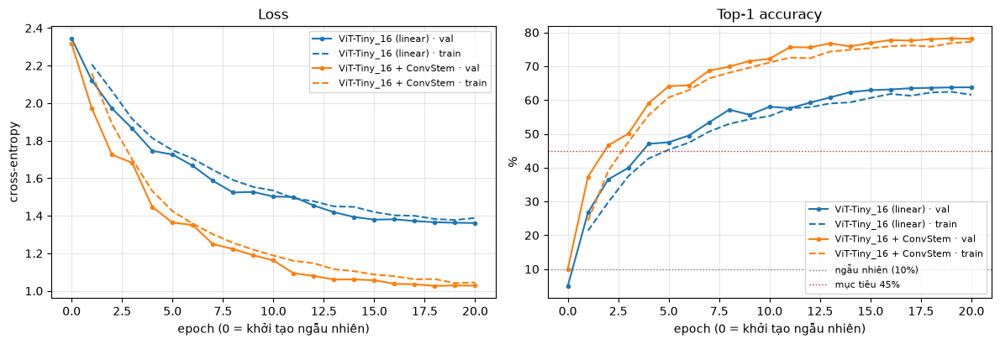

run                         epoch0 val  epoch1 val   cuối val   best val  best ep  s/epoch
ViT-Tiny_16 (linear)             5.02%      26.70%     63.77%     63.77%       20       63
ViT-Tiny_16 + ConvStem          10.01%      37.32%     78.11%     78.24%       19       89


In [6]:
import statistics
from pathlib import Path

# Thư mục kết quả của hai run ở mục 5 và 6 (chính là giá trị run_training trả về)
OUT = Path(cfg.experiment.output_dir)
run_base, run_conv = OUT / "vit_tiny_16", OUT / "vit_tiny_16_convstem"
runs = {"ViT-Tiny_16 (linear)": run_base, "ViT-Tiny_16 + ConvStem": run_conv}
histories = {name: load_history(d) for name, d in runs.items()}
plot_history(histories, save_path=OUT / "compare_curves.png")
plt.show()

print(f"{'run':<26}{'epoch0 val':>12}{'epoch1 val':>12}{'cuối val':>11}{'best val':>11}{'best ep':>9}{'s/epoch':>9}")
for name, rows in histories.items():
    best = max(rows, key=lambda r: r["val_acc"])
    sec = statistics.median(r["epoch_time_s"] for r in rows if r["epoch"] > 0)
    print(f"{name:<26}{rows[0]['val_acc']:>11.2f}%{rows[1]['val_acc']:>11.2f}%"
          f"{rows[-1]['val_acc']:>10.2f}%{best['val_acc']:>10.2f}%{best['epoch']:>9}{sec:>9.0f}")

## 8. Đánh giá trên tập test

Imagenette chỉ có hai split (train / val), nên split **val** được dùng làm tập test: nó không bao giờ tham gia cập nhật trọng số. `eval.py` nạp `best.pt` của mỗi run cùng đúng config lúc train.

[vit_tiny_16] best.pt (epoch 20) | loss 1.3615 | top-1 63.77% | top-5 94.09%
   tench               78.04%
   English springer    73.16%
   cassette player     64.71%
   chain saw           41.45%
   church              58.44%
   French horn         68.27%
   garbage truck       69.92%
   gas pump            59.43%
   golf ball           51.63%
   parachute           73.33%


[vit_tiny_16_convstem] best.pt (epoch 19) | loss 1.0289 | top-1 78.24% | top-5 97.43%
   tench               89.66%
   English springer    88.61%
   cassette player     77.03%
   chain saw           62.18%
   church              79.71%
   French horn         82.99%
   garbage truck       83.55%
   gas pump            66.11%
   golf ball           70.18%
   parachute           83.08%



Confusion matrix: ViT-Tiny_16 (linear)


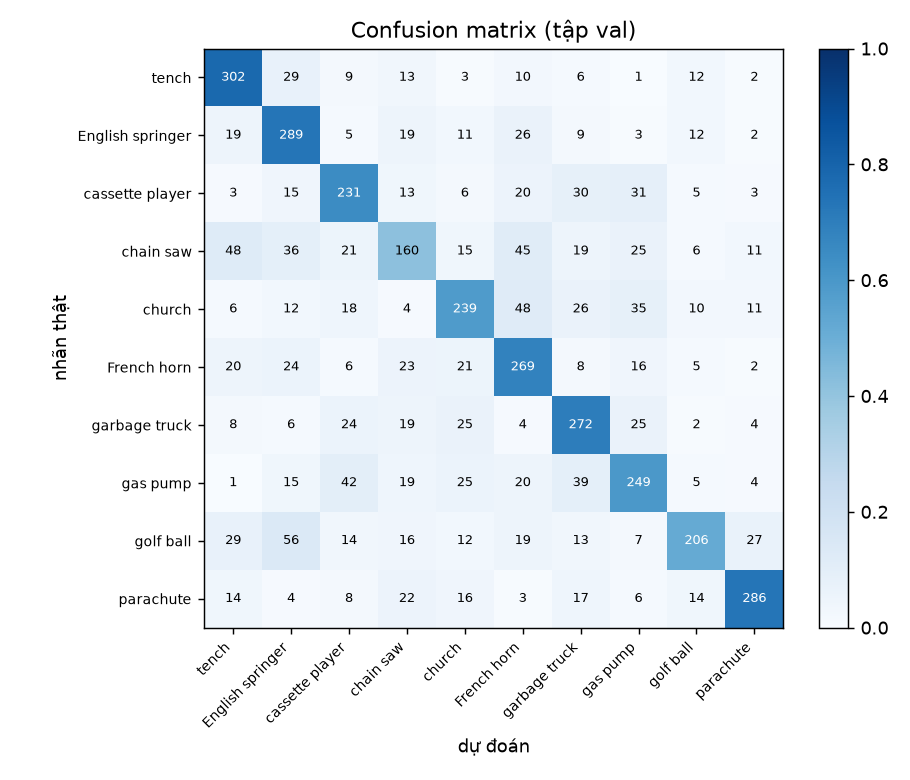


Confusion matrix: ViT-Tiny_16 + ConvStem


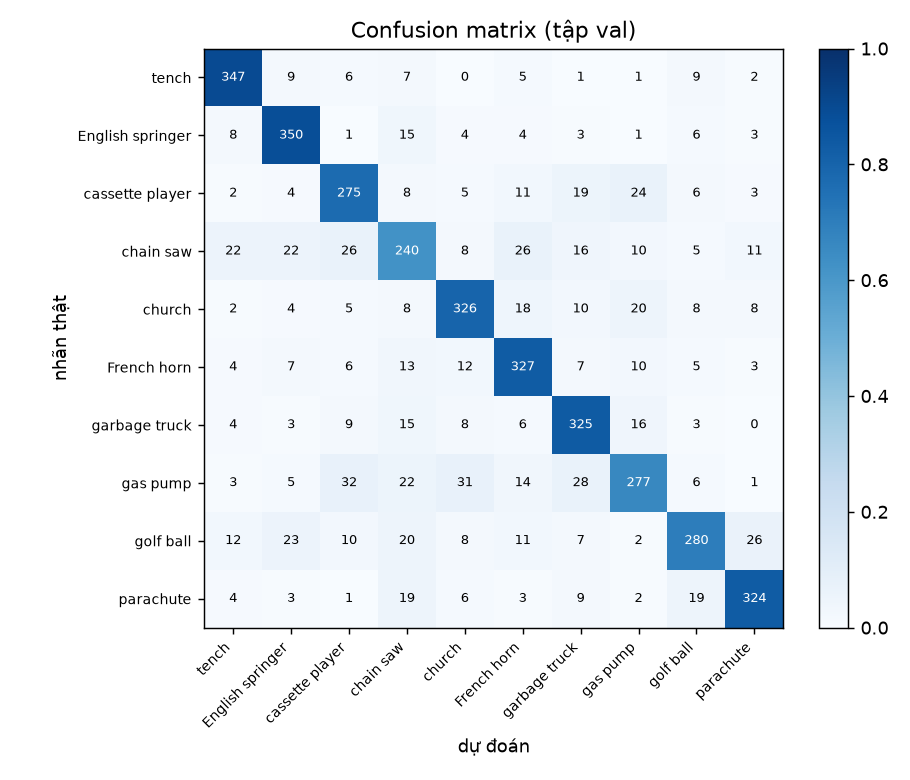

In [7]:
results = {name: run_eval(d) for name, d in runs.items()}
for name, d in runs.items():
    print(f"\nConfusion matrix: {name}")
    display(Image(filename=str(d / "confusion_matrix.png"), width=520))

## 9. Position embedding đã học

Mỗi ô nhỏ trong lưới 14×14 ứng với một patch (hàng r, cột c) và là bản đồ cosine similarity giữa position embedding của patch đó với mọi patch khác. Lúc khởi tạo, bảng `nn.Embedding(197, 64)` hoàn toàn ngẫu nhiên và **không biết** patch nào nằm cạnh patch nào. Nếu sau khi train mỗi bản đồ sáng quanh đúng vị trí của nó, nghĩa là model đã **tự học ra cấu trúc 2D** của ảnh chỉ từ chỉ số 0..196.

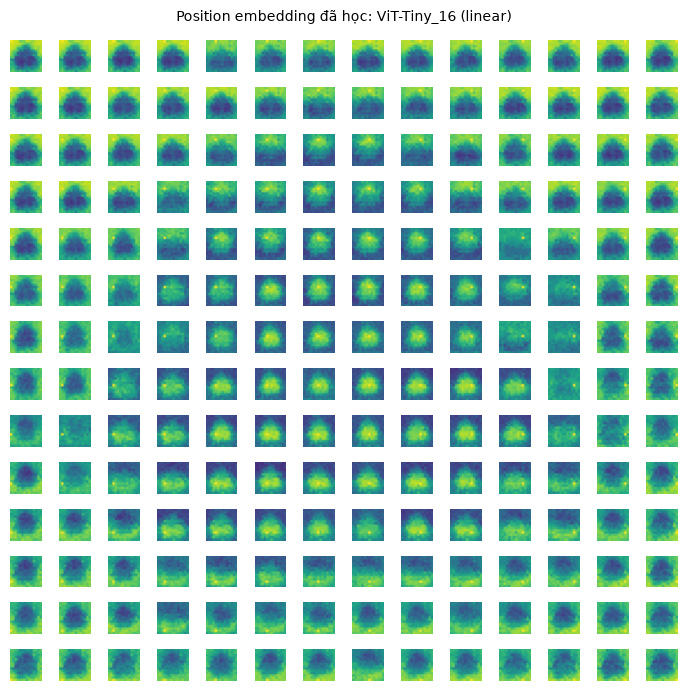

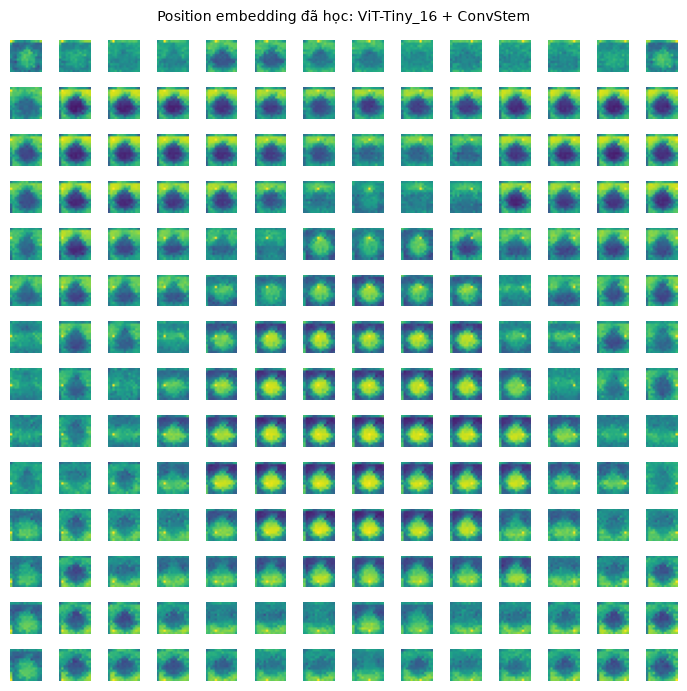

In [8]:
from utils import load_checkpoint
for name, d in runs.items():
    c = load_config(str(d / "config.yaml"))
    m = build_model(c.model, c.data.image_size, c.data.num_classes)
    load_checkpoint(d / "best.pt", m)
    plot_position_similarity(m.tokens.pos_embed.weight, m.grid_size,
                             title=f"Position embedding đã học: {name}",
                             save_path=d / "position_similarity.png")
    plt.show()

## 10. Attention map của token [CLS]

Với mỗi ảnh val: ảnh gốc, rồi attention của [CLS] lên 196 patch chồng lên ảnh, theo hai cách:
- **rollout**: nhân dồn attention (cộng thêm residual) qua cả 4 layer;
- **last_layer**: hàng [CLS] của attention ở layer cuối, trung bình 4 head.

Hai model được vẽ trên **cùng các ảnh** để so sánh.

Hai ảnh được chọn là ảnh mà **cả hai model đều đoán đúng** với độ tin cậy cao, để thấy model nhìn vào đâu khi nó nhận ra vật thể. Ca dự đoán sai được phân tích ở mục 17.

ViT-Tiny_16 (linear)


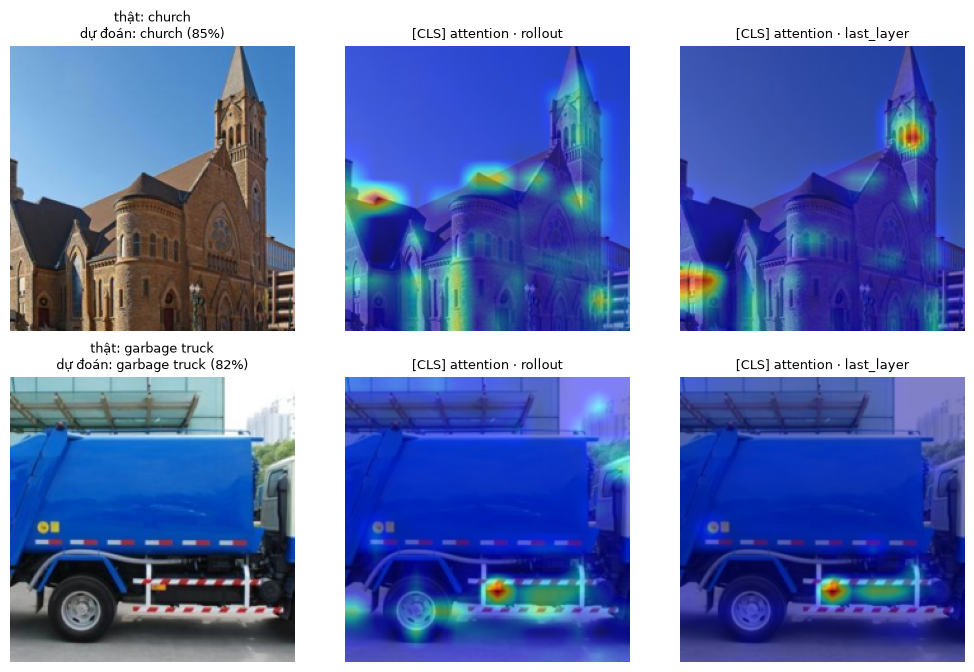

ViT-Tiny_16 + ConvStem


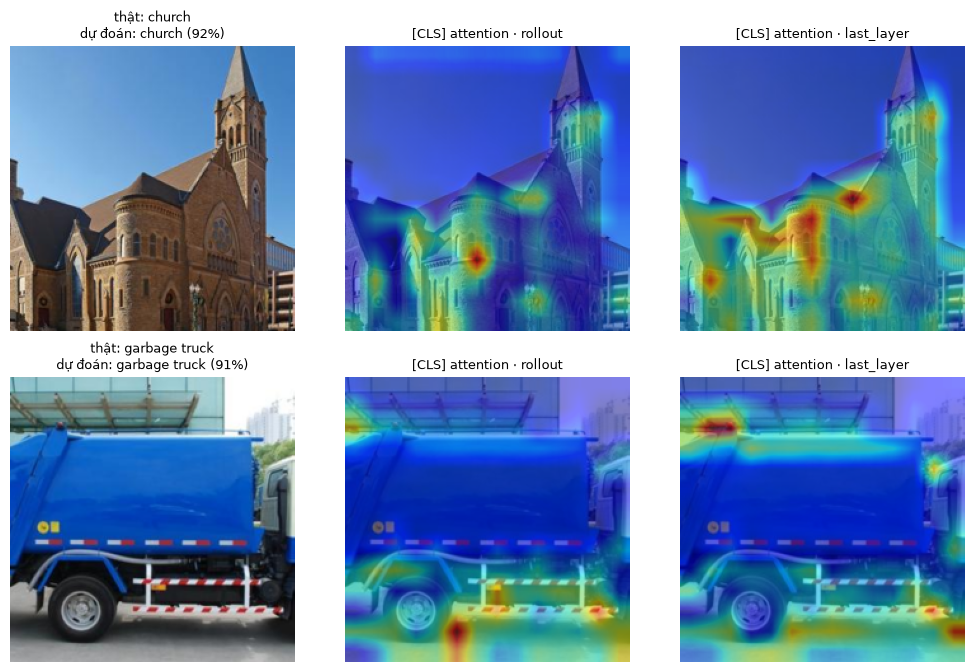

In [9]:
IDX = [1690, 2492]   # church, garbage truck: ảnh mà cả hai model đều đoán đúng (đổi tuỳ ý)
for name, d in runs.items():
    print(name)
    run_visualize(d, indices=IDX, save_name="attention_cls.png")
    plt.show()

## 11. Cải tiến 2: Locality trong Transformer block (LeFF)

Conv Stem chỉ đưa **tính cục bộ** vào ở đầu vào. Bên trong 4 TransformerBlock, attention vẫn là toàn cục và MLP xử lý **từng token riêng lẻ**, nên model phải tự học "các patch cạnh nhau thì liên quan" từ chỉ ~9.5k ảnh.

**LeFF** (Locality-enhanced Feed-Forward, CeiT / LocalViT) chèn một **depthwise conv 3×3** vào giữa `fc1` và `fc2` của MLP:

```text
x (B, 197, 64) --fc1--> (B, 197, 128)
   tách [CLS] (B, 1, 128) | 196 patch (B, 196, 128) --xếp lưới--> (B, 128, 14, 14)
   --DWConv 3×3, groups=128--> (B, 128, 14, 14) --duỗi + nối [CLS]--> (B, 197, 128)
   --GELU--> --fc2--> (B, 197, 64)
```

- Giữ nguyên D = 64, 4 head, 4 layer, MLP hidden = 128 như đề bài; chỉ thêm 128·9 + 128 = **1,280 tham số mỗi block** (+5,120 tổng, +2.6%).
- [CLS] không có vị trí trên lưới nên đi thẳng qua, không qua conv.
- Code: `LocalityFeedForward` trong `models/components.py`; bật bằng `model.mlp_type: leff`. `TransformerBlock` không đổi vì nó nhận khối FFN được truyền vào.

Để tách riêng tác dụng của từng cải tiến, chúng ta huấn luyện thêm 2 run và có một **ablation 2×2**, tất cả cùng config, cùng seed và 20 epoch:

| | MLP (gốc) | LeFF |
|---|---|---|
| **stem linear** | `vit_tiny_16` (mục 5) | `vit_tiny_16_leff` (mục 12) |
| **ConvStem** | `vit_tiny_16_convstem` (mục 6) | `vit_tiny_16_convstem_leff` (mục 13) |

In [10]:
# Import bổ sung cho mục 11–18
import statistics, time
from pathlib import Path
import torch
import matplotlib.pyplot as plt
from IPython.display import Image, display

from configs import load_config
from models import build_model
from utils import count_parameters, format_shape_table, load_history, trace_shapes
from utils.architecture import plot_architecture_comparison
from utils.visualize import plot_history
from train import run_training
from eval import run_eval
from visualize_attention import run_compare, run_visualize

CONFIG = "configs/config.yaml"
OUT = Path("outputs")
run_base, run_conv = OUT / "vit_tiny_16", OUT / "vit_tiny_16_convstem"
base_cfg = load_config(CONFIG)
IMG, K = base_cfg.data.image_size, base_cfg.data.num_classes

cấu hình              stem    blocks      tổng
linear + MLP        49,216   133,888   196,554
linear + LeFF       49,216   139,008   201,674
conv + MLP          80,088   133,888   227,426
conv + LeFF         80,088   139,008   232,546

module               loại                 shape vào         shape ra        
-------------------  -------------------  ----------------  ----------------
blocks.0.mlp.fc1     Linear               (2, 197, 64)      (2, 197, 128)   
blocks.0.mlp.dwconv  Conv2d               (2, 128, 14, 14)  (2, 128, 14, 14)
blocks.0.mlp.act     GELU                 (2, 197, 128)     (2, 197, 128)   
blocks.0.mlp.drop    Dropout              (2, 197, 128)     (2, 197, 128)   
blocks.0.mlp.fc2     Linear               (2, 197, 128)     (2, 197, 64)    
blocks.0.mlp.drop    Dropout              (2, 197, 64)      (2, 197, 64)    
blocks.0.mlp         LocalityFeedForward  (2, 197, 64)      (2, 197, 64)    


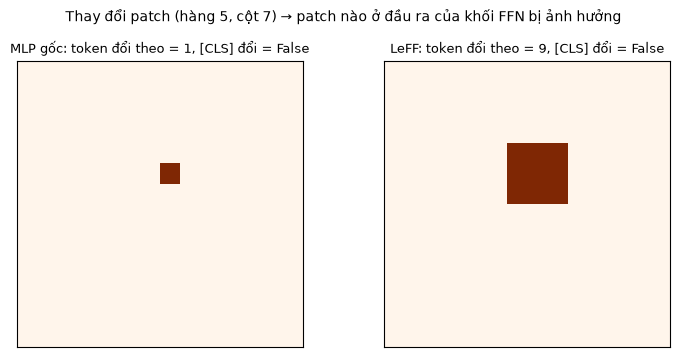

In [11]:
# Số tham số của 4 cấu hình: chỉ stem và FFN thay đổi
VARIANTS = {
    "linear + MLP":   ["model.stem=linear", "model.mlp_type=standard"],
    "linear + LeFF":  ["model.stem=linear", "model.mlp_type=leff"],
    "conv + MLP":     ["model.stem=conv",   "model.mlp_type=standard"],
    "conv + LeFF":    ["model.stem=conv",   "model.mlp_type=leff"],
}
print(f"{'cấu hình':<16}{'stem':>10}{'blocks':>10}{'tổng':>10}")
for name, ov in VARIANTS.items():
    c = count_parameters(build_model(load_config(CONFIG, ov).model, IMG, K))
    print(f"{name:<16}{c['stem']:>10,}{c['blocks']:>10,}{c['total']:>10,}")

# Shape đi qua khối LeFF của block đầu tiên
cfg_leff = load_config(CONFIG, ["model.mlp_type=leff"])
m_leff = build_model(cfg_leff.model, IMG, K).eval()
rows = trace_shapes(m_leff, torch.randn(2, 3, IMG, IMG), max_depth=4)
print("\n" + format_shape_table([r for r in rows if r[0].startswith("blocks.0.mlp")]))

# Kiểm chứng tính cục bộ: thay đổi 1 patch (hàng 5, cột 7) rồi xem token đầu ra nào đổi theo
G, r0, c0 = m_leff.grid_size, 5, 7
x = torch.randn(1, G * G + 1, cfg_leff.model.embed_dim)
x2 = x.clone(); x2[0, 1 + r0 * G + c0] += 1.0
m_std = build_model(base_cfg.model, IMG, K).eval()
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.6))
for ax, (name, ffn) in zip(axes, [("MLP gốc", m_std.blocks[0].mlp), ("LeFF", m_leff.blocks[0].mlp)]):
    with torch.no_grad():
        diff = (ffn(x2) - ffn(x)).abs().sum(-1)[0]        # (T,)
    ax.imshow(diff[1:].reshape(G, G) > 1e-6, cmap="Oranges")
    ax.set_title(f"{name}: token đổi theo = {int((diff[1:] > 1e-6).sum())}, [CLS] đổi = {bool(diff[0] > 1e-6)}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"Thay đổi patch (hàng {r0}, cột {c0}) → patch nào ở đầu ra của khối FFN bị ảnh hưởng", fontsize=10)
plt.tight_layout(); plt.show()

## 12. Huấn luyện ViT-Tiny_16 + LeFF (stem linear)

Cùng config với mục 5, chỉ đổi `model.mlp_type=leff`. Log vẫn bắt đầu bằng **epoch 0** (model khởi tạo ngẫu nhiên) và loss của iteration 1.

In [12]:
t0 = time.time()
run_leff = run_training(load_config(CONFIG, ["model.stem=linear", "model.mlp_type=leff",
                                             "experiment.name=vit_tiny_16_leff"]))
print(f"Tổng thời gian: {(time.time() - t0) / 60:.1f} phút")

11:38:41 | Run 'vit_tiny_16_leff' | ViT-Tiny_16 | stem=linear | device=cpu


11:38:41 | Dữ liệu: 9469 ảnh train, 3925 ảnh val, 295 iter/epoch, batch_size=32


11:38:41 | Số tham số: stem=49,216, tokens=12,672, blocks=139,008, norm=128, head=650, total=201,674


11:38:58 | Luồng shape qua model:
module            loại                       shape vào         shape ra    
----------------  -------------------------  ----------------  ------------
stem.proj         Linear                     (2, 196, 768)     (2, 196, 64)
stem              PatchEmbedding             (2, 3, 224, 224)  (2, 196, 64)
tokens.pos_embed  Embedding                  (197,)            (197, 64)   
tokens.dropout    Dropout                    (2, 197, 64)      (2, 197, 64)
tokens            ClsTokenPositionEmbedding  (2, 196, 64)      (2, 197, 64)
blocks.0          TransformerBlock           (2, 197, 64)      (2, 197, 64)
blocks.1          TransformerBlock           (2, 197, 64)      (2, 197, 64)
blocks.2          TransformerBlock           (2, 197, 64)      (2, 197, 64)
blocks.3          TransformerBlock           (2, 197, 64)      (2, 197, 64)
norm              LayerNorm                  (2, 197, 64)      (2, 197, 64)
head.net          Linear                     (2, 64)  

11:39:03 | epoch  0 (khởi tạo ngẫu nhiên, chưa train) | val loss 2.3278 | val acc 10.09% | val acc5 48.15%


...

11:57:38 | epoch 20/20 | iter  250/295 | loss 1.5137 (avg 1.3776) | acc avg 62.02% | lr 1.05e-06 | 0.23s/iter


11:57:48 | epoch 20/20 | iter  295/295 | loss 1.1784 (avg 1.3746) | acc avg 62.29% | lr 1.00e-06 | 0.23s/iter


11:57:53 | ==> epoch 20/20 | train loss 1.3746 acc 62.29% | val loss 1.3467 acc 63.82% acc5 94.65% | best 63.87% | 67s


11:57:53 | Xong 20 epoch trong 18.8 phút | best val acc 63.87% | kết quả ở outputs\vit_tiny_16_leff


Tổng thời gian: 19.2 phút


## 13. Huấn luyện ViT-Tiny_16 + ConvStem + LeFF

Kết hợp cả hai cải tiến: locality ở đầu vào (ConvStem) và trong mọi block (LeFF).

In [13]:
t0 = time.time()
run_conv_leff = run_training(load_config(CONFIG, ["model.stem=conv", "model.mlp_type=leff",
                                                  "experiment.name=vit_tiny_16_convstem_leff"]))
print(f"Tổng thời gian: {(time.time() - t0) / 60:.1f} phút")

11:57:55 | Run 'vit_tiny_16_convstem_leff' | ViT-Tiny_16 | stem=conv | device=cpu


11:57:55 | Dữ liệu: 9469 ảnh train, 3925 ảnh val, 295 iter/epoch, batch_size=32


11:57:55 | Số tham số: stem=80,088, tokens=12,672, blocks=139,008, norm=128, head=650, total=232,546


11:58:12 | Luồng shape qua model:
module            loại                       shape vào         shape ra       
----------------  -------------------------  ----------------  ---------------
stem.convs        Sequential                 (2, 3, 224, 224)  (2, 64, 14, 14)
stem.proj         Conv2d                     (2, 64, 14, 14)   (2, 64, 14, 14)
stem              ConvStem                   (2, 3, 224, 224)  (2, 196, 64)   
tokens.pos_embed  Embedding                  (197,)            (197, 64)      
tokens.dropout    Dropout                    (2, 197, 64)      (2, 197, 64)   
tokens            ClsTokenPositionEmbedding  (2, 196, 64)      (2, 197, 64)   
blocks.0          TransformerBlock           (2, 197, 64)      (2, 197, 64)   
blocks.1          TransformerBlock           (2, 197, 64)      (2, 197, 64)   
blocks.2          TransformerBlock           (2, 197, 64)      (2, 197, 64)   
blocks.3          TransformerBlock           (2, 197, 64)      (2, 197, 64)   
norm              

11:58:21 | epoch  0 (khởi tạo ngẫu nhiên, chưa train) | val loss 2.3123 | val acc 10.09% | val acc5 50.34%


...

12:28:15 | epoch 20/20 | iter  250/295 | loss 1.2640 (avg 1.0464) | acc avg 77.24% | lr 1.05e-06 | 0.24s/iter


12:28:25 | epoch 20/20 | iter  295/295 | loss 1.0589 (avg 1.0475) | acc avg 77.27% | lr 1.00e-06 | 0.24s/iter


12:28:32 | ==> epoch 20/20 | train loss 1.0475 acc 77.27% | val loss 1.0346 acc 77.71% acc5 97.50% | best 77.73% | 71s


12:28:32 | Xong 20 epoch trong 30.2 phút | best val acc 77.73% | kết quả ở outputs\vit_tiny_16_convstem_leff


Tổng thời gian: 30.6 phút


## 14. So sánh hai kiến trúc: bản gốc vs ConvStem + LeFF

Sơ đồ được **sinh tự động từ chính hai model** (`utils/architecture.py`): shape lấy từ một lần forward thật, số tham số đếm từ module. Khối màu cam là khối khác bản gốc; cột phải so sánh chi tiết khối feed-forward MLP và LeFF.

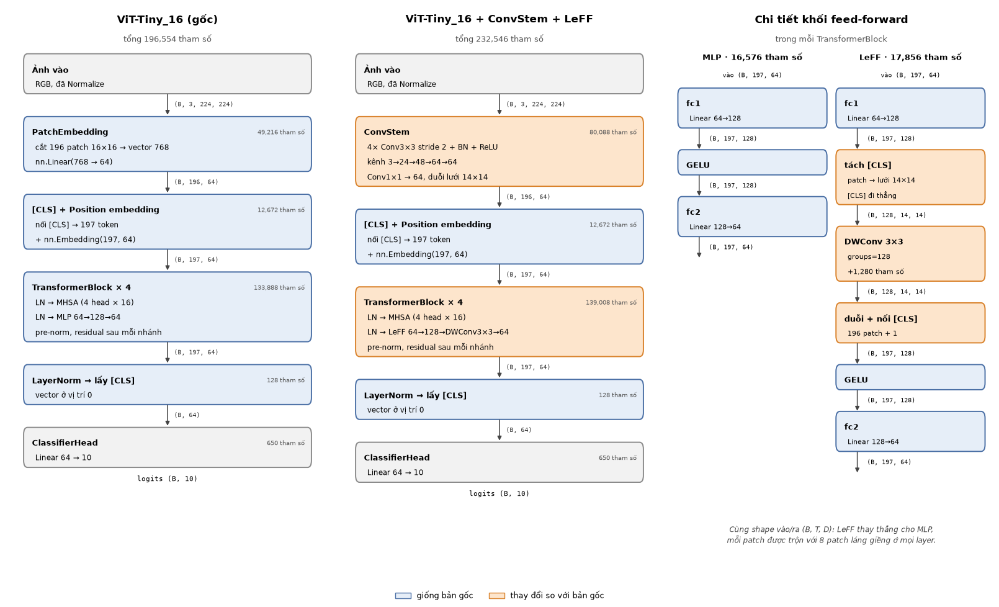

In [14]:
arch_models = {}
for name, d in [("ViT-Tiny_16 (gốc)", run_base), ("ViT-Tiny_16 + ConvStem + LeFF", run_conv_leff)]:
    c = load_config(str(d / "config.yaml"))           # đúng config đã dùng để train run đó
    arch_models[name] = build_model(c.model, c.data.image_size, c.data.num_classes)
plot_architecture_comparison(arch_models, torch.randn(2, 3, IMG, IMG),
                             save_path=OUT / "architecture_comparison.png")
plt.show()

## 15. Kết quả 4 cấu hình (ablation 2×2)

Đường cong chỉ vẽ **val** cho gọn (train/val của từng run nằm ở bảng bên dưới và ở mục 7). Thời gian mỗi epoch dùng **trung vị**: trong lúc chạy run ConvStem (mục 6) máy bị sleep qua đêm, nên epoch 6 của run đó có thời gian thực ~13 giờ dù chỉ tính toán ~1.5 phút.

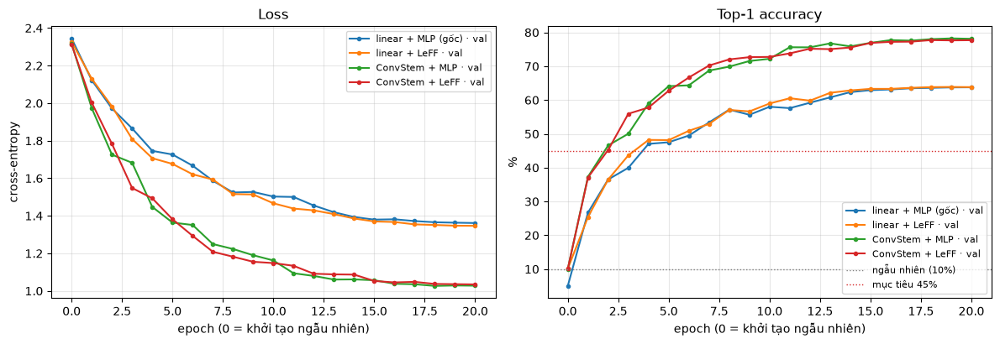

cấu hình              tham số     ep0     ep1     ep5    ep10    ep20   best (ep) train ep20  s/epoch
-----------------------------------------------------------------------------------------------------
linear + MLP (gốc)    196,554    5.0%   26.7%   47.5%   58.0%   63.8%   63.77% (20)      61.6%       63
linear + LeFF         201,674   10.1%   25.4%   48.2%   59.0%   63.8%   63.87% (19)      62.3%       54
ConvStem + MLP        227,426   10.0%   37.3%   64.1%   72.2%   78.1%   78.24% (19)      77.2%       89
ConvStem + LeFF       232,546   10.1%   37.1%   62.8%   72.8%   77.7%   77.73% (18)      77.3%       79

Best val top-1 (%) theo ablation 2×2:
                   MLP      LeFF    Δ LeFF
linear           63.77     63.87     +0.10
ConvStem         78.24     77.73     -0.51
Δ ConvStem      +14.47    +13.86


In [15]:
RUNS = {
    "linear + MLP (gốc)": run_base,
    "linear + LeFF":      run_leff,
    "ConvStem + MLP":     run_conv,
    "ConvStem + LeFF":    run_conv_leff,
}
histories = {name: load_history(d) for name, d in RUNS.items()}
plot_history(histories, save_path=OUT / "compare_curves_4runs.png", show_train=False)
plt.show()

params = {name: count_parameters(build_model(load_config(str(d / "config.yaml")).model, IMG, K))["total"]
          for name, d in RUNS.items()}
hdr = f"{'cấu hình':<20}{'tham số':>9}{'ep0':>8}{'ep1':>8}{'ep5':>8}{'ep10':>8}{'ep20':>8}{'best (ep)':>12}{'train ep20':>11}{'s/epoch':>9}"
print(hdr); print("-" * len(hdr))
best = {}
for name, rows in histories.items():
    v = {r["epoch"]: r["val_acc"] for r in rows}
    b = max(rows, key=lambda r: r["val_acc"]); best[name] = b["val_acc"]
    sec = statistics.median(r["epoch_time_s"] for r in rows if r["epoch"] > 0)
    print(f"{name:<20}{params[name]:>9,}{v[0]:>7.1f}%{v[1]:>7.1f}%{v[5]:>7.1f}%{v[10]:>7.1f}%{v[20]:>7.1f}%"
          f"{b['val_acc']:>8.2f}% ({b['epoch']:>2}){rows[-1]['train_acc']:>10.1f}%{sec:>9.0f}")

print("\nBest val top-1 (%) theo ablation 2×2:")
print(f"{'':<12}{'MLP':>10}{'LeFF':>10}{'Δ LeFF':>10}")
for stem, a, b in [("linear", "linear + MLP (gốc)", "linear + LeFF"), ("ConvStem", "ConvStem + MLP", "ConvStem + LeFF")]:
    print(f"{stem:<12}{best[a]:>10.2f}{best[b]:>10.2f}{best[b] - best[a]:>+10.2f}")
print(f"{'Δ ConvStem':<12}{best['ConvStem + MLP'] - best['linear + MLP (gốc)']:>+10.2f}"
      f"{best['ConvStem + LeFF'] - best['linear + LeFF']:>+10.2f}")

## 16. Đánh giá trên tập test

Đánh giá `best.pt` của cả 4 run trên split val (đóng vai trò tập test, không tham gia cập nhật trọng số), kèm accuracy theo từng lớp.

[vit_tiny_16] best.pt (epoch 20) | loss 1.3615 | top-1 63.77% | top-5 94.09%
   tench               78.04%
   English springer    73.16%
   cassette player     64.71%
   chain saw           41.45%
   church              58.44%
   French horn         68.27%
   garbage truck       69.92%
   gas pump            59.43%
   golf ball           51.63%
   parachute           73.33%


[vit_tiny_16_leff] best.pt (epoch 19) | loss 1.3473 | top-1 63.87% | top-5 94.60%
   tench               78.55%
   English springer    70.63%
   cassette player     66.67%
   chain saw           42.23%
   church              59.41%
   French horn         66.24%
   garbage truck       70.95%
   gas pump            59.43%
   golf ball           51.38%
   parachute           74.10%


[vit_tiny_16_convstem] best.pt (epoch 19) | loss 1.0289 | top-1 78.24% | top-5 97.43%
   tench               89.66%
   English springer    88.61%
   cassette player     77.03%
   chain saw           62.18%
   church              79.71%
   French horn         82.99%
   garbage truck       83.55%
   gas pump            66.11%
   golf ball           70.18%
   parachute           83.08%


[vit_tiny_16_convstem_leff] best.pt (epoch 18) | loss 1.0371 | top-1 77.73% | top-5 97.55%
   tench               90.96%
   English springer    87.09%
   cassette player     77.59%
   chain saw           59.84%
   church              76.28%
   French horn         81.98%
   garbage truck       84.32%
   gas pump            65.63%
   golf ball           75.44%
   parachute           78.97%



lớp                     linear + MLP     linear + LeFF    ConvStem + MLP   ConvStem + LeFF
tench                          78.0%             78.6%             89.7%             91.0%
English springer               73.2%             70.6%             88.6%             87.1%
cassette player                64.7%             66.7%             77.0%             77.6%
chain saw                      41.5%             42.2%             62.2%             59.8%
church                         58.4%             59.4%             79.7%             76.3%
French horn                    68.3%             66.2%             83.0%             82.0%
garbage truck                  69.9%             71.0%             83.5%             84.3%
gas pump                       59.4%             59.4%             66.1%             65.6%
golf ball                      51.6%             51.4%             70.2%             75.4%
parachute                      73.3%             74.1%             83.1%             79.0

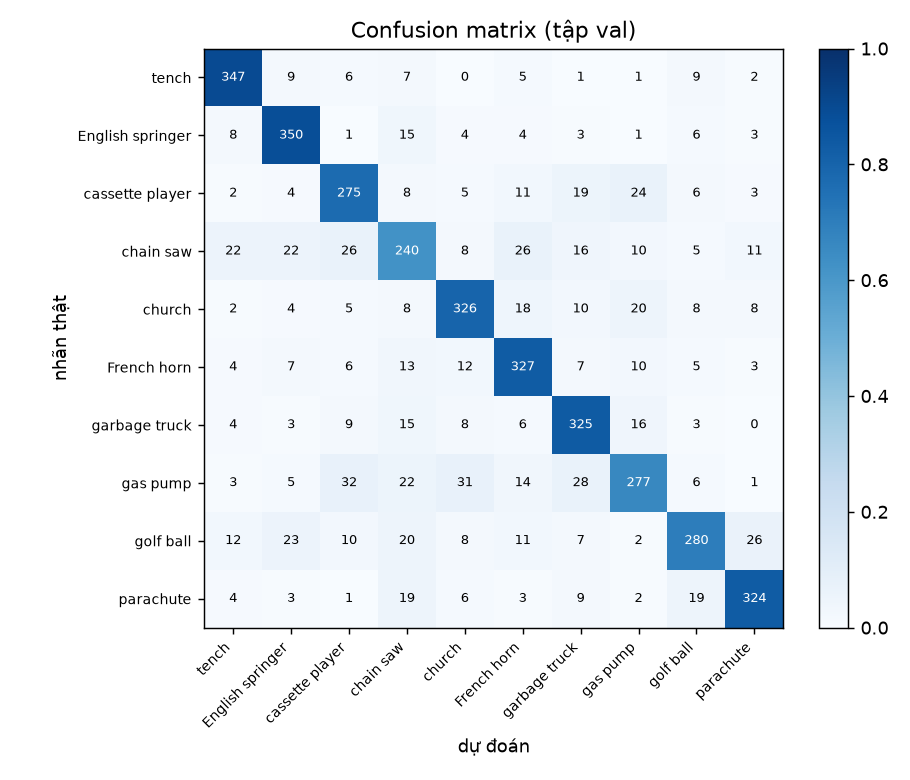

In [16]:
results = {name: run_eval(d) for name, d in RUNS.items()}

classes = list(next(iter(results.values()))["per_class_acc"].keys())
short = {name: name.replace(" (gốc)", "") for name in RUNS}
print(f"\n{'lớp':<18}" + "".join(f"{short[n]:>18}" for n in RUNS))
for cls in classes:
    print(f"{cls:<18}" + "".join(f"{results[n]['per_class_acc'][cls]:>17.1f}%" for n in RUNS))
print(f"{'TỔNG top-1':<18}" + "".join(f"{results[n]['test_acc']:>17.2f}%" for n in RUNS))
print(f"{'TỔNG top-5':<18}" + "".join(f"{results[n]['test_acc5']:>17.2f}%" for n in RUNS))

best_name = max(results, key=lambda n: results[n]["test_acc"])
print(f"\nConfusion matrix của run tốt nhất: {best_name}")
display(Image(filename=str(RUNS[best_name] / "confusion_matrix.png"), width=520))

## 17. Attention map của token [CLS]: 4 cấu hình

Trước tiên là hình riêng của hai run mới (rollout và last_layer, giống mục 10). Sau đó là **cùng 4 ảnh val cho cả 4 cấu hình** (Attention Rollout) để so sánh trực tiếp vùng mà mỗi model tập trung vào; dấu ✗ đánh dấu dự đoán sai.

Cách chọn 4 ảnh (dựa trên dự đoán của hai run **đầu tiên**, chọn **trước khi** huấn luyện hai run LeFF nên không thiên vị LeFF):
- **#1690** (church), **#2492** (garbage truck): cả linear + MLP và ConvStem + MLP đều đoán đúng, độ tin cậy cao;
- **#2191** (French horn): chỉ ConvStem đoán đúng, bản gốc đoán nhầm thành church;
- **#1450** (chain saw): cả hai đều đoán sai, là một trường hợp thất bại để phân tích.

linear + LeFF


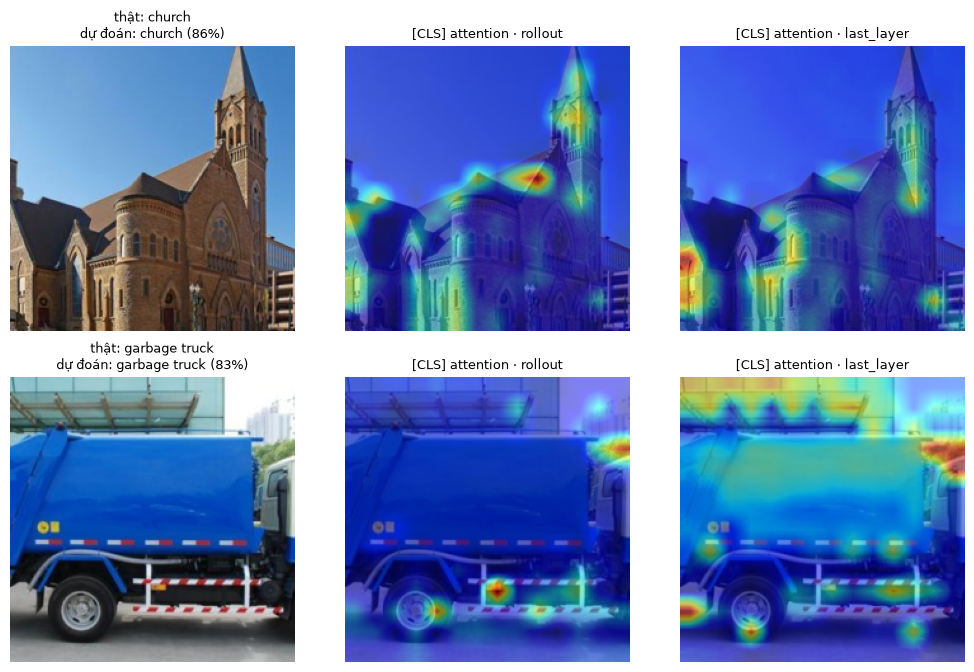

ConvStem + LeFF


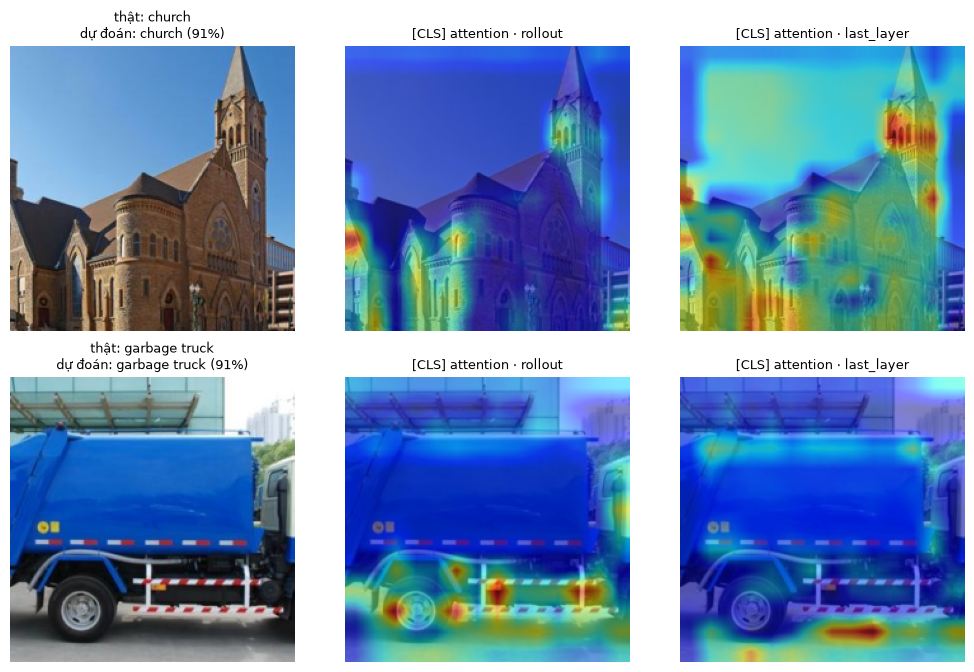

In [17]:
IDX = [1690, 2492]                      # cùng ảnh với mục 10
for name, d in [("linear + LeFF", run_leff), ("ConvStem + LeFF", run_conv_leff)]:
    print(name)
    run_visualize(d, indices=IDX, save_name="attention_cls.png")
    plt.show()

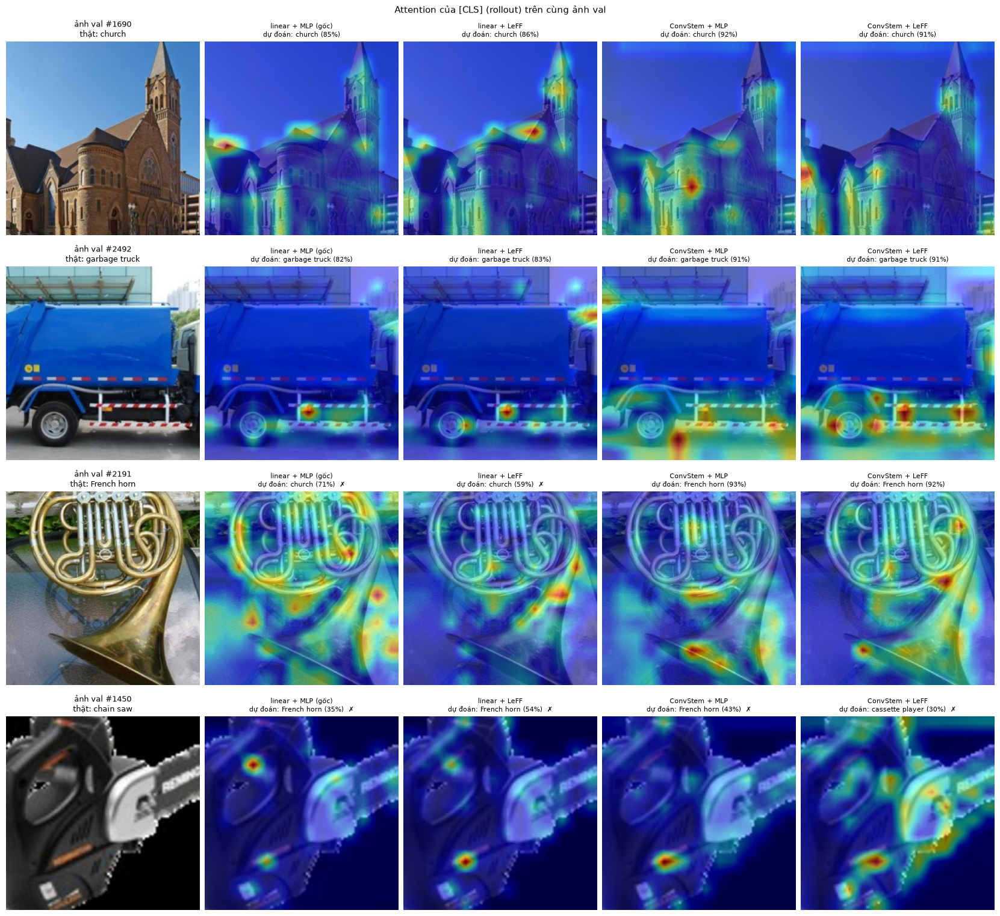

In [18]:
IDX_CMP = [1690, 2492, 2191, 1450]
run_compare(RUNS, indices=IDX_CMP, method="rollout", save_path=OUT / "attention_compare_4runs.png")
plt.show()

## 18. Thảo luận

### 18.1 Kết quả chính

| Cấu hình | Tham số | Best val top-1 (epoch) | Top-5 | Vượt 45% từ epoch | Vượt 70% từ epoch |
|---|---:|---:|---:|---:|---:|
| linear + MLP (**bản gốc**, ViT-Tiny_16) | 196,554 | **63.77%** (20) | 94.09% | 4 | — |
| linear + LeFF | 201,674 | 63.87% (19) | 94.60% | 4 | — |
| ConvStem + MLP | 227,426 | **78.24%** (19) | 97.43% | 2 | 9 |
| ConvStem + LeFF | 232,546 | 77.73% (18) | 97.55% | 2 | 7 |

Ngẫu nhiên = 10%. Cả 4 cấu hình đều **vượt yêu cầu 45%**: bản gốc đạt 63.77%, gấp ~6.4 lần mức ngẫu nhiên, và đã vượt 45% từ epoch 4.

### 18.2 Bằng chứng huấn luyện from scratch

- **Epoch 0** (trước khi cập nhật trọng số nào): val loss 2.31–2.35 ≈ ln(10) = 2.303, val accuracy 5.0–10.1%. Đây đúng là mức của một bộ phân loại 10 lớp đoán ngẫu nhiên.
- **Iteration đầu tiên** của epoch 1 có loss 2.29–2.37 ở cả 4 run.
- Loss giảm và accuracy tăng dần qua từng epoch (mục 7, 15); không có bước nhảy đột ngột kiểu nạp trọng số có sẵn. Log đầy đủ nằm ở `outputs/<run>/train_log.txt`.

### 18.3 Vì sao ~64% là mức bình thường cho bản gốc

1. **Dữ liệu rất ít so với nhu cầu của ViT.** Bài báo ViT gốc chỉ vượt CNN khi pretrain trên 14M–300M ảnh; khi train trên dữ liệu nhỏ, ViT thua ResNet vì **không có inductive bias cục bộ**. Ở đây chỉ có 9,469 ảnh train.
2. **Model rất nhỏ.** 197k tham số, D = 64, MLP chỉ gấp 2 lần D. Để so sánh, ViT-Ti của DeiT có D = 192 và 5.7M tham số, train 300 epoch trên 1.28M ảnh ImageNet.
3. **Model đang underfit, không phải overfit.** Ở epoch 20, train accuracy (61.6%, đo khi có augmentation + dropout) vẫn **thấp hơn** val accuracy (63.8%), và đường val vẫn còn nhích lên ở những epoch cuối dù learning rate đã giảm về gần 0. Giới hạn đến từ năng lực model và số epoch, không phải từ việc học thuộc dữ liệu.
4. **Bản gốc dựa nhiều vào màu sắc / bối cảnh.** Cặp nhầm nhiều nhất là *golf ball → English springer* (56 ảnh), hợp lý vì cả hai thường có nền cỏ xanh; tiếp theo là *church → French horn* và *chain saw → tench / French horn* (45–48 ảnh). Lớp khó nhất là chain saw (41.5%) và golf ball (51.6%).

### 18.4 ConvStem: cải tiến có hiệu quả rõ rệt (+14.5 điểm)

- Cùng config và cùng 20 epoch, ConvStem nâng best val từ 63.77% lên **78.24%**, chỉ tốn thêm 31k tham số (+16%). Mức tăng này lớn gấp ~20 lần sai số chuẩn của phép đo (±0.7 điểm trên 3,925 ảnh).
- **Hội tụ nhanh hơn nhiều:** ConvStem ở epoch 5 (64.1%) đã bằng bản gốc ở epoch 20.
- **Cải thiện ở cả 10 lớp**, nhiều nhất ở church (+21.3), chain saw (+20.7) và golf ball (+18.6). Cặp nhầm *golf ball → English springer* (56 ảnh ở bản gốc) không còn nằm trong 5 cặp nhầm nhiều nhất; với ConvStem, nhầm lẫn chủ yếu dồn vào gas pump (với cassette player, church, garbage truck: 28–32 ảnh mỗi cặp).
- **Giải thích:** patch + `nn.Linear` buộc mỗi token 16×16 phải được mô tả bằng **một phép chiếu tuyến tính duy nhất**, không có phi tuyến. Các đặc trưng cấp thấp (cạnh, kết cấu) vì vậy rất khó học từ 9.5k ảnh. ConvStem trích đặc trưng cục bộ phân cấp (conv chồng lấn + BN + ReLU) **trước** khi vào Transformer, nên các block attention làm việc trên token "giàu thông tin" hơn. Kết quả này khớp với Xiao et al. (2021).
- **Chi phí:** thời gian mỗi epoch tăng khoảng 1.4 lần (trung vị 89 s so với 63 s). Đây là ước lượng thô vì các run chạy trên cùng một CPU trong những điều kiện tải khác nhau.

### 18.5 LeFF: không có cải thiện đo được trong thí nghiệm này

- Thêm LeFF cho **+0.10 điểm** với stem linear và **−0.51 điểm** với ConvStem. Cả hai chênh lệch đều **nhỏ hơn sai số chuẩn** của phép đo (±0.7–0.8 điểm), và mỗi cấu hình chỉ chạy **một seed**, nên **không thể kết luận LeFF tốt hơn hay kém hơn**. Chênh lệch theo từng lớp (ví dụ golf ball +5.2, parachute −4.1 ở cặp ConvStem) cũng nằm trong mức dao động ±2–2.5 điểm của ~390 ảnh/lớp.
- Đáng chú ý, ConvStem + LeFF dẫn trước ở **giữa** quá trình train (epoch 3: 55.9% so với 50.0%; vượt 70% từ epoch 7 thay vì 9), nhưng hai đường hội tụ về cùng một mức ở epoch 20. Có thể LeFF giúp hội tụ sớm hơn một chút, nhưng một seed là chưa đủ để khẳng định.
- **Giả thuyết** vì sao lợi ích không xuất hiện (chưa được kiểm chứng):
  1. **Nút thắt nằm bên trong patch, không phải giữa các patch.** ConvStem (+14 điểm) cho thấy điều còn thiếu là đặc trưng cấp thấp *trong* từng ô 16×16. LeFF trộn thông tin giữa các token láng giềng ở độ phân giải 14×14, tức mỗi bước là 16 pixel; quan hệ thô này attention + position embedding đã học được phần nào.
  2. **Phiên bản LeFF tối giản.** CeiT dùng thêm BatchNorm sau depthwise conv và hidden dim rộng hơn nhiều (768 so với 128 ở đây), và được đánh giá với 300 epoch trên ImageNet. Với 128 kênh × 9 trọng số mỗi block và chỉ 20 epoch, hiệu ứng có thể quá nhỏ để thấy.
  3. **Viền lưới:** 52/196 token nằm ở viền và nhận zero-padding, nên phần conv của chúng bị "pha loãng".
- **Thí nghiệm tiếp theo nên làm:** chạy 3 seed mỗi cấu hình để đo phương sai; thêm BatchNorm sau DWConv; thử kernel 5×5; train 50–100 epoch.

### 18.6 Attention map của [CLS] (mục 10, 17)

- **Ảnh đoán đúng (#1690 church, #2492 garbage truck):** cả 4 model đều chú ý vào vật thể chứ không phải bầu trời hay nền. Bản linear tập trung vào vài điểm nóng (mép mái, thanh chắn bên hông xe). Bản ConvStem trải attention rộng hơn trên cấu trúc vật thể (mặt tiền nhà thờ, gầm xe và bánh xe).
- **#2191 French horn** là ví dụ rõ nhất về tác dụng của ConvStem. Hai model stem linear đoán sai (church) và attention **tản mát ra nền** (mặt bàn kính, góc ảnh). Hai model ConvStem đoán đúng với độ tin cậy 92–93% và attention tập trung vào **miệng loa và ống đồng**.
- **#1450 chain saw** (cả 4 đều sai): ảnh là một ảnh sản phẩm cận cảnh trên nền đen, có viền răng cưa do cắt ghép, khác xa phân phối ảnh huấn luyện. Attention rơi vào phần thân/tay cầm tối màu, và model đoán French horn / cassette player, khớp với việc chain saw là lớp khó nhất.
- **Lưu ý khi đọc attention map:** attention không phải là lời giải thích nhân quả; rollout là một phép xấp xỉ; lưới chỉ 14×14 nên bản đồ thô. Các ảnh được chọn theo tiêu chí ghi ở mục 10 và 17, trước khi train hai run LeFF.

### 18.7 Position embedding đã học (mục 9)

Bảng `nn.Embedding(197, 64)` xuất phát hoàn toàn ngẫu nhiên. Sau 20 epoch, nó đã học được một cấu trúc không gian rõ ràng, nhưng chủ yếu ở dạng **"trung tâm so với rìa"**: patch ở giữa giống các patch ở giữa, patch ở rìa giống vùng rìa, kèm một đỉnh nhỏ ở đúng vị trí của chính nó. Nó **chưa** thành một lưới 2D sắc nét như ViT pretrain trên dữ liệu lớn. Điều này hợp lý: ảnh Imagenette thường đặt vật thể ở giữa, và 9.5k ảnh × 20 epoch chưa đủ tín hiệu để học vị trí chi tiết. Ở bản ConvStem, vùng trung tâm tách bạch hơn.

### 18.8 Kết luận

- Mô hình ViT-Tiny_16 tự xây dựng, huấn luyện from scratch, đạt **63.77%** top-1, vượt yêu cầu 45%.
- **ConvStem** là cải tiến hiệu quả: **78.24%** (+14.5 điểm), hội tụ nhanh gấp ~4 lần tính theo epoch, chỉ +16% tham số.
- **LeFF** đúng yêu cầu thiết kế (giữ D = 64 / 4 head / 4 layer / MLP 128, chỉ +1,280 tham số mỗi block, tính cục bộ được kiểm chứng ở mục 11) nhưng **không cải thiện độ chính xác đo được** trong 20 epoch với một seed.
- Cấu hình được đề xuất: **ViT-Tiny_16 + ConvStem** (MLP chuẩn), vì có độ chính xác cao nhất và ít tham số hơn bản có LeFF.